<a href="https://colab.research.google.com/github/dubosqchloe-creator/thelook-europe-analyse/blob/main/notebooks/01_EDA_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/Gestionnaire data/Datagong /DA_Projet_TheLook/thelook_fr_women_2023_2024.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
df.head()

,order_id,order_item_id,product_id,item_created_at,item_status,sale_price,cost,category,department,brand,product_name,order_status,order_created_at,shipped_at,delivered_at,user_id,gender,country,state,city
0,19425,28112,6983,2023-01-01 06:18:03+00:00,Shipped,29.500000,16.048000,Shorts,Women,Fox,Fox Juniors Momentum Short,Shipped,2022-12-29 10:00:00+00:00,2022-12-30 11:29:00+00:00,NaN,15644,F,France,Centre-Val de Loire,Corquilleroy
1,19425,28113,10597,2023-01-01 06:44:58+00:00,Shipped,20.000000,10.000000,Intimates,Women,Wacoal,Wacoal Women's B-Smooth Bralette,Shipped,2022-12-29 10:00:00+00:00,2022-12-30 11:29:00+00:00,NaN,15644,F,France,Centre-Val de Loire,Corquilleroy
2,4710,6730,11792,2023-01-03 04:44:50+00:00,Complete,38.000000,18.468000,Intimates,Women,American Apparel,American Apparel Striped Chiffon Tank,Complete,2023-01-03 08:12:00+00:00,2023-01-03 09:14:00+00:00,2023-01-04 03:03:00+00:00,3853,F,France,Île-de-France,Paris
3,16618,24006,329,2023-01-03 15:13:39+00:00,Complete,27.990000,16.402140,Tops & Tees,Women,Tri-Mountain,Tri-Mountain Women's 3/4-Sleeve Pique Knit Pol...,Complete,2023-01-03 18:58:00+00:00,2023-01-05 13:23:00+00:00,2023-01-09 10:25:00+00:00,13422,F,France,Hauts-de-France,Comines
4,4710,6731,5295,2023-01-05 06:43:09+00:00,Complete,56.880001,29.577601,Pants & Capris,Women,Lauren by Ralph Lauren,Lauren Ralph Lauren Velour Pants,Complete,2023-01-03 08:12:00+00:00,2023-01-03 09:14:00+00:00,2023-01-04 03:03:00+00:00,3853,F,France,Île-de-France,Paris


# I - Compréhension des données

## 1 - Dictionnaire

In [3]:



# Création d'un tableau contenant le nom des colonnes, leur type, un exemple et la définition
dico = pd.DataFrame({
    "colonne" : df.columns,
    "type" : df.dtypes.astype(str),
    "exemple" : df.iloc[0],
    "definition" : "",
})



# Création d'un dictionnaire contenant les définitions qui seron inclues dans les colonnes
definition = {
    "order_id" : "Identifiant de la commande",
    "order_item_id" : "Identifiant de l'article commandé dans une commande précise",
    "product_id" : "Identifiant du produit",
    "item_created_at" : "Date et heure de création de l'article commandé",
    "item_status" : "Statut de l'article",
    "sale_price" : "Prix de vente pour calculer le CA",
    "cost" : "Coût d'achat du produit par l'entreprise pour calculer la marge",
    "category" : "Catégorie du produit",
    "department" : "Rayon du produit",
    "brand" : "Marque du produit",
    "product_name" : "Nom du produit",
    "order_status" : "Statut de la commande",
    "order_created_at" : "Date et heure de création de la commande",
    "shipped_at" : "Date et heure d'expédition",
    "delivered_at" : "Date et heure de livraison",
    "user_id" : "Identifiant du client",
    "gender" : "Genre du client",
    "country" : "Pays du client",
    "state" : "Région du client",
    "city" : "Ville du client"
}

dico["definition"] = dico["colonne"].map(definition)

dico

# Les colonnes de dates sont lues comme du texte (object) : elles seront converties au format date à l'étape 3.

# L devise n'est pas précisée dans la consigne. Les montants (sale_price, cost) sont traités comme des euros.

,colonne,type,exemple,definition
order_id,order_id,int64,19425,Identifiant de la commande
order_item_id,order_item_id,int64,28112,Identifiant de l'article commandé dans une com...
product_id,product_id,int64,6983,Identifiant du produit
item_created_at,item_created_at,object,2023-01-01 06:18:03+00:00,Date et heure de création de l'article commandé
item_status,item_status,object,Shipped,Statut de l'article
sale_price,sale_price,float64,29.5,Prix de vente pour calculer le CA
cost,cost,float64,16.048,Coût d'achat du produit par l'entreprise pour ...
category,category,object,Shorts,Catégorie du produit
department,department,object,Women,Rayon du produit
brand,brand,object,Fox,Marque du produit


## 2 - Granularité : que représente une ligne ?

In [4]:
# Nombre de lignes
nb_lignes = len(df)
print(f"Il y a {nb_lignes} lignes dans le fichier.")

nb_cdes_differentes = df["order_id"].nunique()
print(f"Il y a {nb_cdes_differentes} commandes différentes dans le fichier.")


# Nombre d'article par commande : maximum, minimum, moyen
articles_cde = df.groupby("order_id")["order_item_id"].count()


articles_max = articles_cde.max()
print(f"Le nombre d'articles maximum par commande est de : {articles_max}.")
articles_min = articles_cde.min()
print(f"Le nombre d'articles minimum par commande est de : {articles_min}.")

articles_moyens = articles_cde.mean()
print(f"Le nombre d'articles moyen par commande est de : {round(articles_moyens,2)}.")



Il y a 1679 lignes dans le fichier.
Il y a 1117 commandes différentes dans le fichier.
Le nombre d'articles maximum par commande est de : 4.
Le nombre d'articles minimum par commande est de : 1.
Le nombre d'articles moyen par commande est de : 1.5.


### Conclusion sur la granularité
Chaque ligne de fichier représente un article commandé.
Deux lignes avec le même `order_id` ont des `order_item_id` différents car cela représente deux articles d'une même commande. Dans ce contexte, il ne faudra pas les traiter comme des doublons.
Pour compter les commandes, il faut donc utiliser`.nunique()` et non `len` qui compterait le nombre d'articles.


# II - Contrôle qualité


## 1 - Recherche des valeurs manquantes

In [5]:
manquants = df.isna().sum()
manquants = manquants[manquants > 0]
pd.DataFrame({
    "nb_manquants": manquants,
    "pourcentage": (manquants / len(df) * 100).round(1)
})



,nb_manquants,pourcentage
brand,2,0.1
shipped_at,546,32.5
delivered_at,1043,62.1


In [6]:
# Vérification des vides "shipped_at" :Création d'un tableau croisé pour comprendre dans quel cas les cases son vides.

pd.crosstab(df["item_status"], df["shipped_at"].isna())

#shipped_at est vide pour les statuts "Cancelled" et "Processing" ce qui est normal puisque l'article n'est pas expédié, car annulé ou pas encore expédié car c'est en cours.

shipped_at,False,True
item_status,,
Cancelled,0,240
Complete,425,0
Processing,0,306
Returned,211,0
Shipped,497,0


In [7]:
# Vérification des vides "delivered_at" :Création d'un tableau croisé pour comprendre dans quel cas les cases son vides."""

pd.crosstab(df["item_status"], df["delivered_at"].isna())

# Même processus avec delivered_at qui est vide pour "Cancelled", "Processing" et "Shipped" ce qui est normal puisqu'un article annulé,en cours de préparation ou envoyé ne peut être livré.

delivered_at,False,True
item_status,,
Cancelled,0,240
Complete,425,0
Processing,0,306
Returned,211,0
Shipped,0,497


In [8]:
# Je crée une variable qui contient la liste des noms de produit qui ont une marque vide.
noms = df[df["brand"].isna()]["product_name"]

# Je regarde si les produits apparaissent ailleurs dans les données et si oui, je récupère la marque
print(df[df["product_name"].isin(noms)][["product_name","brand"]])



                                           product_name brand
320   The Very Hungry Caterpillar Classic Book Women...   NaN
1237                      Husky Animal Hat with Mittens   NaN


In [9]:
# Résultat : les produits n'apparaissent nulle part ailleurs, dans ce contexte, je remplace simplement les marques vides par "Inconnue" :
df["brand"] = df['brand'].fillna("Inconnue")

# Et je vérifie qu'il n'y a plus de vide dans "brand" :
df["brand"].isna().sum()

np.int64(0)

## 2 -  Recherche des doublons


In [10]:
print(df.duplicated().sum())

print(df["order_item_id"].duplicated().sum())

# Aucune ligne n'est entièrement dupliquée et aucun "order_item_id" en double

0
0


## 3 - Conversion des dates au format date

In [11]:
# Création d'une liste contenant les colonnes de dates
colonnes_dates = ["item_created_at", "order_created_at", "shipped_at", "delivered_at"]

# Création d'un boucle qui nomme chaque élément de la liste "col" et lui applique un format date
for col in colonnes_dates :
  df[col] = pd.to_datetime(df[col],format="ISO8601")

#Vérification du format
print(df[colonnes_dates].dtypes)

# Délimitation des bornes temporelles
bornes = (df['item_created_at'] >= "2023-01-01") & (df['item_created_at'] < "2025-01-01")
df[~bornes]
# Toutes les lignes ont une date item_created_at comprise entre le 01/01/2023 et le 31/12/2024 : les bornes temporelles du périmètre sont respectées.

item_created_at     datetime64[ns, UTC]
order_created_at    datetime64[ns, UTC]
shipped_at          datetime64[ns, UTC]
delivered_at        datetime64[ns, UTC]
dtype: object


,order_id,order_item_id,product_id,item_created_at,item_status,sale_price,cost,category,department,brand,product_name,order_status,order_created_at,shipped_at,delivered_at,user_id,gender,country,state,city


## 4 - Contrôle du périmètre


In [12]:
# Vérification du périmètre établi par la consigne : articles commandés en France dans le rayon "Women"
print(f"Le nombre de lignes est de {len(df)}")

pays = df["country"].value_counts()
print(pays)

rayon = df["department"].value_counts()
print(rayon)



Le nombre de lignes est de 1679
country
France    1679
Name: count, dtype: int64
department
Women    1679
Name: count, dtype: int64


### Conclusion sur le contrôle du périmètre
Après vérification, il y a 1679 lignes 'France' et 'Women'ce qui correspond au nombre de lignes total du fichier. Toutes les lignes respectent donc le périmètre.
La vérification de la période sera effectuée en partie 3 (Conversion des dates).

## 5 - Création de la table des vente valides


In [13]:

ventes = df[df["item_status"] == "Complete"]
ventes.shape


(425, 20)

## 6 - Cohérence des dates


In [14]:

# livré avant d'être expédié
verif_livraison_expedition = (df["delivered_at"] < df["shipped_at"]).sum()
print(f"Il y a {verif_livraison_expedition} lignes dont la date de livraison est antérieure à la date d'expédition.")

# Les dates sont cohérentes

#  Expédié avant d'être créé
verif_expedition_creation = (df["shipped_at"] < df["item_created_at"]).sum()


print(f"Il y a {verif_expedition_creation} lignes dont la date d'expédition est antérieure à la date de création soit {round(verif_expedition_creation / len(df)*100)} %.")


# 375 lignes soit 22% du fichier ont une date d'expédition antérieure à la date de création de l'article.

anomalie_date = df[(df["shipped_at"] < df["item_created_at"])]

difference_date = anomalie_date["item_created_at"] - anomalie_date["shipped_at"]
print(difference_date.describe())

# La différence maximum est de 3 jours et 22h.


# Nombre de lignes impactées par le changement d'année
nb_lignes_chgmt_annee = (df["item_created_at"].dt.year != df["order_created_at"].dt.year).sum()
print(f"Il y a {nb_lignes_chgmt_annee} lignes qui changent d'année.")

# Nombre de lignes impactées par le changement de mois
nb_lignes_chgmt_mois = (df["item_created_at"].dt.month != df["order_created_at"].dt.month).sum()
print(f"Il y a {nb_lignes_chgmt_mois} lignes qui changent de mois.")

# Impact sur le CA

ecart_annee = ventes["item_created_at"].dt.year != ventes["order_created_at"].dt.year
nb_lignes_chgmt_annee_ca = ecart_annee.sum()
print(f"Il y a {nb_lignes_chgmt_annee_ca} lignes qui changent d'année dans la table ventes.")

ecart_mois = ventes["item_created_at"].dt.month != ventes["order_created_at"].dt.month
nb_lignes_chgmt_mois_ca = ecart_mois.sum()
print(f"Il y a {nb_lignes_chgmt_mois_ca} lignes qui changent de mois dans la table ventes.")

part_ca = ventes[ecart_mois]["sale_price"].sum() / ventes["sale_price"].sum() *100

print(f"Il y a {round(part_ca,1)} % du CA qui change de mois si on utilise la date de création de l'article au lieu de la date de création de la commande.")

Il y a 0 lignes dont la date de livraison est antérieure à la date d'expédition.
Il y a 375 lignes dont la date d'expédition est antérieure à la date de création soit 22 %.
count                          375
mean     1 days 12:28:43.829333333
std      0 days 23:36:57.908186129
min                0 days 00:07:33
25%         0 days 17:41:31.500000
50%                1 days 10:35:48
75%         2 days 05:16:43.500000
max                3 days 22:27:59
dtype: object
Il y a 2 lignes qui changent d'année.
Il y a 66 lignes qui changent de mois.
Il y a 0 lignes qui changent d'année dans la table ventes.
Il y a 18 lignes qui changent de mois dans la table ventes.
Il y a 4.1 % du CA qui change de mois si on utilise la date de création de l'article au lieu de la date de création de la commande.


### Conclusion sur la cohérence des dates

La comparaison 2023 vs 2024 n'est pas affectée : aucune vente ne change d'année.

L'analyse mois par mois est peu affectée : 18 ventes sur 425 changent de mois, ce qui représente 4,1 % du CA.

Décision : conformément à la consigne, `item_created_at` reste la date de référence. Les variations d'un mois à l'autre seront interprétées avec prudence.


# III - Explorations descriptives

## 1 - Distribution et valeurs aberrantes



In [15]:
print(ventes[["sale_price","cost"]].describe())

# La moyenne est de 55.34€ et la médiane est de 36.29€ ce qui indique que des prix élevés tirent la moyenne vers le haut.
# Le prix minimum est de 1.82€ et le maximum est de 903€ ce qui montre un écart de prix considérable entre les articles.
# 75% des ventes sont en dessous de 62.36€ mais l'article le plus cher est à 903 ce qui indique que la majorité des ventes d'articles sont à des prix modérés.

articles_max = ventes[["category","brand","product_name","sale_price","cost"]].sort_values(by=["sale_price","cost"], ascending=False).head()
print(f"Les 5 articles les plus chers :")
print(articles_max)
# Les articles les plus cher sont des vêtements type veste (4 sur 5) ou robe.

articles_min = ventes[["category","brand","product_name","sale_price","cost"]].sort_values(by=["sale_price","cost"]).head()
print(f"Les 5 articles les moins chers :")
print(articles_min)
# Les articles les moins chers sont des accessoires (3 sur 5) ou des t-shirts.


# Valeurs impossibles
val_inf_zero = (df[["sale_price","cost"]] <= 0) .sum()
print(f"Les valeurs inférieures ou égales à 0:")
print(val_inf_zero)

val_sup = (df["cost"] > df["sale_price"]).sum()
print(f"Les lignes où le coût est supérieur au prix de vente:")
print(val_sup)





       sale_price        cost
count  425.000000  425.000000
mean    55.347294   26.617999
std     71.414762   33.699885
min      1.820000    0.749840
25%     18.969999    8.735630
50%     36.290001   17.973780
75%     62.360001   29.577601
max    903.000000  437.052001
Les 5 articles les plus chers :
               category           brand  \
468   Outerwear & Coats  The North Face   
1442  Outerwear & Coats       Arc'teryx   
509             Dresses  Rebecca Taylor   
1053  Blazers & Jackets          McGinn   
1097  Outerwear & Coats            BGSD   

                                           product_name  sale_price  \
468       The North Face Denali Down Womens Jacket 2013   903.00000   
1442                   Arc'teryx Women's Beta AR Jacket   475.00000   
509                   Rebecca Taylor Women's Lace Dress   395.00000   
1053               McGinn Women's Clara Textured Blazer   330.00000   
1097  BGSD Women's New Zealand Lambskin Leather Walk...   319.98999   

            

### Conclusion sur la distribution et les valeurs aberrantes
Les prix maximums et minimums sont plausibles et ne relèvent pas des valeurs aberrantes.
En effet l'article à 903 est une veste 'The North Face' et l'article à 1.82 est un bonnet 'Star'.
Il n'y a pas de valeurs impossibles comme des prix inférieurs ou égaux à 0 ou des prix de vente inférieurs au coût.
Dans ce contexte, ces valeurs sont correctes et seront donc conservées.

### Graphique de distribution


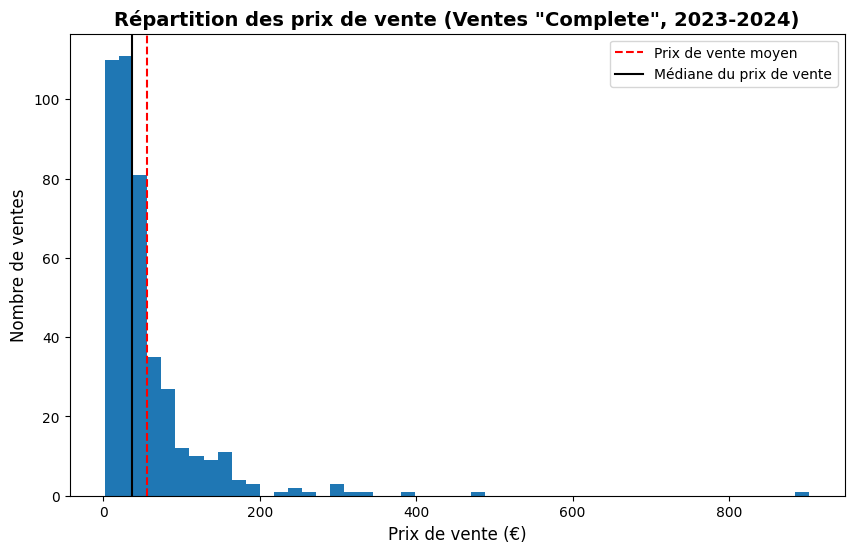

In [16]:
# Création des variables de la moyenne et la médiane
moyenne_saleprice = ventes["sale_price"].mean()
mediane_saleprice = ventes["sale_price"].median()

# Création de l'histogramme avec une ligne verticale pour la moyenne et la médiane
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(ventes['sale_price'], bins=50)
ax.axvline(moyenne_saleprice, color="red", linestyle="--", label="Prix de vente moyen")
ax.axvline(mediane_saleprice, color="black", linestyle="-", label="Médiane du prix de vente")

ax.set_title('Répartition des prix de vente (Ventes "Complete", 2023-2024)', fontsize=14, fontweight='bold')
ax.set_xlabel('Prix de vente (€)', fontsize=12)
ax.set_ylabel('Nombre de ventes', fontsize=12)
ax.legend()
plt.show()

### Conclusion graphique de distribution
75% des ventes se concentre dans la tranche de prix de vente 0-62€.
Au-delà, le nombre de ventes baisse drastiquement.
Ce graphique confirme les données de la distribution à savoir qu'il y a peu de ventes concernant les articles les plus chers : la majorité des ventes concernent des articles à tarifs modérés (en dessous de 62€).
La moyenne se situe après la médiane car le prix élevé de certains articles tire cette dernière vers le haut.

## 2 - Contribution par marque

In [17]:
# Nombre de marques différentes
nb_marques = ventes["brand"].nunique()
print(f"Il y a {nb_marques} marques différentes.")

# CA par marque (top 5 affiché)
ca_par_marque = ventes.groupby("brand")["sale_price"].sum().sort_values(ascending=False)
print("Les 5 marques avec le CA le plus élevé :")
print(ca_par_marque.head())

# Part du CA des 5 premières marques
ca_total = ventes["sale_price"].sum()
part_ca_marques = ca_par_marque / ca_total * 100
print("Part du CA des 5 premières marques (%) :")
print(round(part_ca_marques.head(), 2))

# Nombre d'articles vendus par marque (top 5 affiché)
nb_ventes_marques = ventes.groupby("brand")["order_item_id"].count().sort_values(ascending=False)
print("Les 5 marques qui ont vendu le plus d'articles :")
print(nb_ventes_marques.head())

# Comparaison The North Face / Allegra K
print("Nombre d'articles vendus par The North Face :")
print(nb_ventes_marques["The North Face"])
print("CA d'Allegra K :")
print(round(ca_par_marque["Allegra K"], 2))

Il y a 271 marques différentes.
Les 5 marques avec le CA le plus élevé :
brand
The North Face    1211.000000
PAIGE              800.970001
Arc'teryx          620.000000
Jones New York     516.989990
Ray-Ban            479.899994
Name: sale_price, dtype: float64
Part du CA des 5 premières marques (%) :
brand
The North Face    5.15
PAIGE             3.41
Arc'teryx         2.64
Jones New York    2.20
Ray-Ban           2.04
Name: sale_price, dtype: float64
Les 5 marques qui ont vendu le plus d'articles :
brand
Allegra K               27
Motherhood Maternity     7
Roxy                     7
SmartWool                6
American Apparel         5
Name: order_item_id, dtype: int64
Nombre d'articles vendus par The North Face :
2
CA d'Allegra K :
310.76


### Conclusion sur la contribution par marque
Il y a 271 marques sur 425 articles vendus. En moyenne chaque marque vend 1.6 article.
La marque la plus vendue est "Allegra K" avec 27 articles vendus. Elle ne fait pas partie des 5 marques au CA le plus élevé avec 310.76€ de CA. On peut en déduire que ses prix sont peu élevés.

On remarque que les 4 marques suivantes qui ont le plus de ventes totalisent entre 5 et 7 articles.

Les 5 marques qui ont le CA le plus élevé représentent environ 15% du CA.  The North Face avec le CA le plus élevé (1211€) n'a effectué que 2 articles vendus, ses prix sont donc particulièrement élevés.

On constate donc que le CA est dispersé entre de nombreuses marques. Aucune marque ne domine.

Il y a donc deux manière de générer du CA : faire de nombreuses ventes à des prix modérés ou vendre quelques articles à des prix très élevés.
